# 15 — Most Improved, 2000-01 → 2025-26: three views of every season

**Question.** For every season since 2000-01, how well could we have called the Most Improved Player (MIP) at three points in time?
1. **End of the previous season:** last season's scoring, minutes, game score, rebounds, assists, team win %, momentum (did he improve, did he finish strongly), age and the second-year flag. Nothing about the summer.
2. **Mid-season:** the race at **day 85** after opening night (about mid-January), using only games up to then.
3. **End of the season:** the full season's changes, as in notebook 10.

**Leak-proof by construction**
- **Every season is predicted by a model trained only on earlier seasons.** Nothing from the season being predicted, or any later one, touches the model.
- **The scoring turning point** (decision D27) is re-chosen inside each training window, by cross-validation over earlier seasons only, from 16, 18, 20, 22 or 24 points a game.
- **The first five seasons (2000-01 → 2004-05) are training data only:** with nothing earlier to learn from, they can't be predicted honestly. So the test covers **21 seasons, 2005-06 → 2025-26**.
- Voting results (Basketball-Reference) give each season's winner and are used to score the lists, never as inputs.

**Differences from notebooks 10–12:** game logs only, because usage, start rate and defensive rating don't exist on NBA.com before 2011-12. No preseason inputs either (no preseason data before 2012-13). Previous winners are included; candidates need one previous season and, in-season, half of their team's games. Penalty λ = 3.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn.mip_history import (DAY_MID, IN_SEASON_FEATURES, MIN_TRAIN_SEASONS, PREV_FEATURES, end_of_previous_frame, in_season_frame,
                                 load_games, player_info, voting, walk_forward)
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style

warnings.filterwarnings("ignore")
apply_style()
games = load_games()
info = player_info()
votes, winners = voting(games)
print(f"{len(games):,} player-games, {games['season'].min()} → {games['season'].max()}; {len(winners)} winners (2000-01 → 2025-26)")

673,732 player-games, 1999-00 → 2025-26; 26 winners (2000-01 → 2025-26)


In [2]:
VIEWS = {"end of previous season": (end_of_previous_frame(games, info, winners), PREV_FEATURES, "ppg_last"),
         f"mid-season (day {DAY_MID})": (in_season_frame(games, info, winners, DAY_MID), IN_SEASON_FEATURES, "base_ppg"),
         "end of season": (in_season_frame(games, info, winners), IN_SEASON_FEATURES, "base_ppg")}
for name, (f, _, _) in VIEWS.items():
    print(f"{name}: {len(f):,} candidate rows, {f.groupby('season').size().median():.0f} a season; winners in the pool: {int(f['mip'].sum())} of {f['season'].nunique()}")
results, picks = {}, {}
for name, (f, feats, level) in VIEWS.items():
    results[name], picks[name] = walk_forward(f, feats, level)

end of previous season: 11,157 candidate rows, 434 a season; winners in the pool: 26 of 26
mid-season (day 85): 7,331 candidate rows, 282 a season; winners in the pool: 26 of 26
end of season: 7,509 candidate rows, 288 a season; winners in the pool: 26 of 26


## 15A — How well does each view do?

In [3]:
real7 = votes[votes["vote_rank"] <= 7].dropna(subset=["player_id"]).groupby("season")["player_id"].apply(lambda s: set(s.astype(int)))
def score(name):
    r, p = results[name], picks[name]
    rk = r["winner's rank"]
    overlap = p.groupby("season").apply(lambda d: len(set(d["player_id"]) & real7.get(d.name, set())))
    return {"seasons": len(r), "winner #1": int((rk == 1).sum()), "in top 3": int((rk <= 3).sum()), "in top 7": int((rk <= 7).sum()),
            "in top 20": int((rk <= 20).sum()), "median winner rank": rk.median(),
            "times better than a blind guess": np.exp(np.mean(np.log(r["winner's chance"] * r["candidates"]))),
            "of our 7 in the real voting top 7": overlap.mean()}
summary = pd.DataFrame({k: score(k) for k in VIEWS}).T
summary.round(2)

,seasons,winner #1,in top 3,in top 7,in top 20,median winner rank,times better than a blind guess,of our 7 in the real voting top 7
end of previous season,21.0,1.0,2.0,2.0,4.0,51.0,2.15,0.76
mid-season (day 85),21.0,4.0,10.0,16.0,19.0,4.0,17.39,3.14
end of season,21.0,7.0,11.0,17.0,20.0,2.0,21.70,3.71


In [4]:
names = {s: f.loc[f["mip"] & (f["season"] == s), "player_name"].iloc[0] for f in [VIEWS["end of season"][0]] for s in results["end of season"].index}
per_season = pd.DataFrame({"winner": names, **{f"rank: {k}": results[k]["winner's rank"].astype(int) for k in VIEWS},
                           **{f"our #1: {k}": picks[k][picks[k]["rank"] == 1].set_index("season")["player_name"] for k in VIEWS}})
per_season

,winner,rank: end of previous season,rank: mid-season (day 85),rank: end of season,our #1: end of previous season,our #1: mid-season (day 85),our #1: end of season
2005-06,Boris Diaw,142,3,2,Gerald Wallace,David West,David West
2006-07,Monta Ellis,49,2,1,Boris Diaw,Deron Williams,Monta Ellis
2007-08,Hedo Turkoglu,182,17,8,Al Jefferson,Rashad McCants,LaMarcus Aldridge
2008-09,Danny Granger,40,16,24,Randy Foye,Chris Duhon,Von Wafer
2009-10,Aaron Brooks,53,2,1,Spencer Hawes,Chris Kaman,Aaron Brooks
2010-11,Kevin Love,107,2,2,Henry Walker,D.J. Augustin,D.J. Augustin
2011-12,Ryan Anderson,52,8,8,JJ Hickson,Jeremy Lin,Jeremy Lin
2012-13,Paul George,13,6,6,DeMarcus Cousins,Jrue Holiday,Stephen Curry
2013-14,Goran Dragic,38,24,17,Tobias Harris,Eric Bledsoe,Eric Bledsoe
2014-15,Jimmy Butler III,34,1,1,Andre Drummond,Jimmy Butler III,Jimmy Butler III


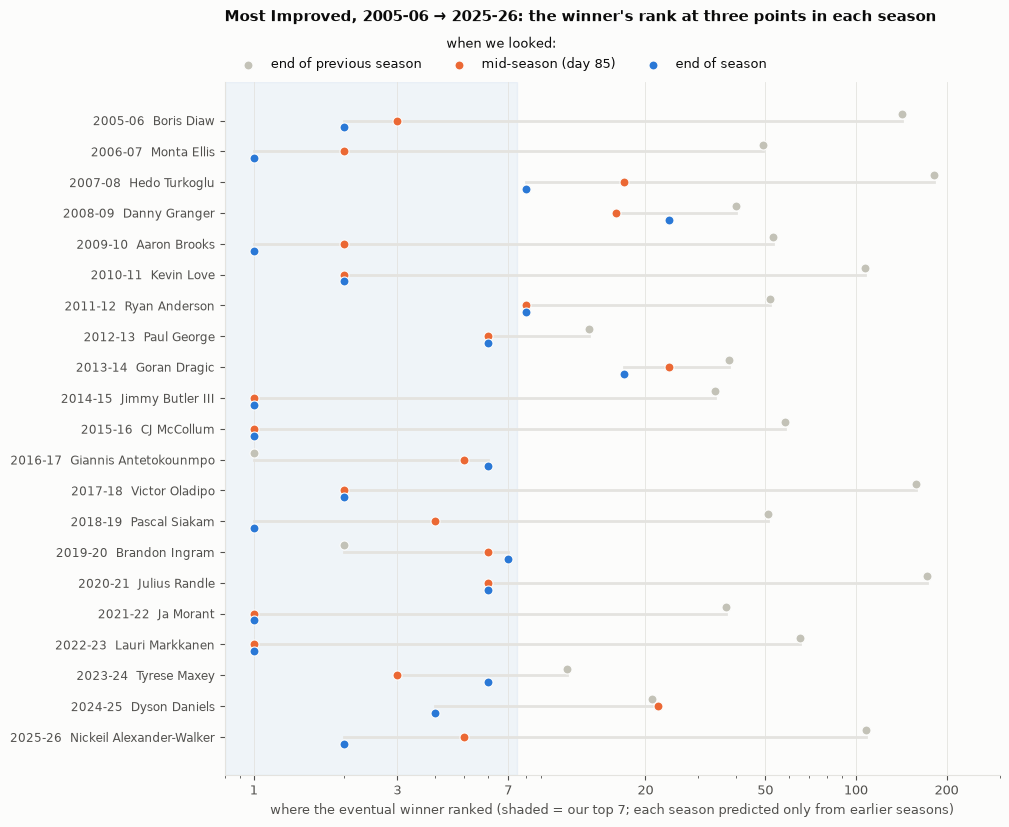

In [5]:
cols = {k: c for k, c in zip(VIEWS, [MUTED, ORANGE, BLUE])}
seasons = list(per_season.index)[::-1]
fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(seasons))
ax.axvspan(0.8, 7.5, color=BLUE, alpha=0.06)
for yi, s in zip(y, seasons):
    r = [per_season.loc[s, f"rank: {k}"] for k in VIEWS]
    ax.plot([min(r), max(r)], [yi, yi], color="#e4e3df", linewidth=2, zorder=1)
for (k, c), dy in zip(cols.items(), [0.22, 0.0, -0.22]):      # small vertical offsets so equal ranks don't hide each other
    ax.scatter([per_season.loc[s, f"rank: {k}"] for s in seasons], y + dy, s=42, color=c, edgecolor=SURFACE,
               linewidth=0.8, zorder=3, label=k)
ax.set_xscale("log"); ax.set_xlim(0.8, 300); ax.set_xticks([1, 3, 7, 20, 50, 100, 200], ["1", "3", "7", "20", "50", "100", "200"])
ax.set_yticks(y, [f"{s}  {per_season.loc[s, 'winner']}" for s in seasons], fontsize=8.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("where the eventual winner ranked (shaded = our top 7; each season predicted only from earlier seasons)")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, title="when we looked:", title_fontsize=9, fontsize=9)
ax.set_title("Most Improved, 2005-06 → 2025-26: the winner's rank at three points in each season", loc="left", pad=44)
fig.savefig(FIG_DIR / "15_mip_three_views_2005_2026.png", dpi=150, bbox_inches="tight")

## 15B — Our top 3 at each point, every season

In [6]:
top3 = pd.concat({k: picks[k][picks[k]["rank"] <= 3].assign(entry=lambda d: d["player_name"] + np.where(d["mip"], " ★", "") + " (" + (100 * d["chance"]).round(0).astype(int).astype(str) + "%)")
                  .groupby("season")["entry"].apply(" · ".join) for k in VIEWS}, axis=1)
top3.insert(0, "winner", per_season["winner"])
top3

,winner,end of previous season,mid-season (day 85),end of season
season,,,,
2005-06,Boris Diaw,Gerald Wallace (6%) · Mo Williams (5%) · Chris...,David West (16%) · Chris Bosh (8%) · Boris Dia...,David West (27%) · Boris Diaw ★ (22%) · Chris ...
2006-07,Monta Ellis,Boris Diaw (12%) · Carlos Boozer (6%) · Josh S...,Deron Williams (16%) · Monta Ellis ★ (14%) · D...,Monta Ellis ★ (12%) · Deron Williams (10%) · G...
2007-08,Hedo Turkoglu,Al Jefferson (21%) · LaMarcus Aldridge (3%) · ...,Rashad McCants (20%) · LaMarcus Aldridge (11%)...,LaMarcus Aldridge (23%) · Rudy Gay (14%) · Ras...
2008-09,Danny Granger,Randy Foye (4%) · Chris Quinn (2%) · Wilson Ch...,Chris Duhon (27%) · Paul Millsap (13%) · Von W...,Von Wafer (15%) · Chris Duhon (7%) · David Lee...
2009-10,Aaron Brooks,Spencer Hawes (3%) · Thaddeus Young (3%) · Ama...,Chris Kaman (13%) · Aaron Brooks ★ (12%) · Dan...,Aaron Brooks ★ (21%) · Danilo Gallinari (13%) ...
2010-11,Kevin Love,Henry Walker (10%) · Andray Blatche (7%) · Dar...,D.J. Augustin (50%) · Kevin Love ★ (11%) · Eri...,D.J. Augustin (45%) · Kevin Love ★ (9%) · Dore...
2011-12,Ryan Anderson,JJ Hickson (4%) · Kevin Love (3%) · Greg Monro...,Jeremy Lin (85%) · James Harden (2%) · Greg Mo...,Jeremy Lin (87%) · Nikola Pekovic (3%) · Jarre...
2012-13,Paul George,DeMarcus Cousins (5%) · Kevin Seraphin (4%) · ...,Jrue Holiday (19%) · Greivis Vasquez (14%) · S...,Stephen Curry (48%) · James Harden (11%) · Gre...
2013-14,Goran Dragic,Tobias Harris (13%) · Nikola Vučević (6%) · La...,Eric Bledsoe (33%) · Lance Stephenson (13%) · ...,Eric Bledsoe (33%) · Lance Stephenson (6%) · R...


In [7]:
# how the last 15 seasons compare with notebook 10's end-of-season model (which also had usage, start rate and defensive rating)
recent = per_season.loc[per_season.index >= "2011-12"]
print(f"2011-12 → 2025-26, end of season, strict, game logs only: winner #1 in {(recent['rank: end of season'] == 1).sum()} of {len(recent)}, "
      f"top 3 in {(recent['rank: end of season'] <= 3).sum()}, median rank {recent['rank: end of season'].median():.0f}")
print("turning point chosen in each training window:", {k: results[k]["turning point used"].value_counts().to_dict() for k in VIEWS})

2011-12 → 2025-26, end of season, strict, game logs only: winner #1 in 5 of 15, top 3 in 7, median rank 4
turning point chosen in each training window: {'end of previous season': {16: 11, 20: 10}, 'mid-season (day 85)': {16: 9, 20: 9, 18: 3}, 'end of season': {16: 11, 20: 5, 18: 5}}


### 15 findings

**The three views, 21 seasons (2005-06 → 2025-26), each season predicted only from earlier seasons**

| When we looked | Winner #1 | In top 3 | In top 7 | Median winner rank | vs a blind guess | Of our 7 in the real voting top 7 |
|---|---|---|---|---|---|---|
| End of previous season | 1 | 2 | 2 | 51 | 2.2× | 0.8 |
| Mid-season (day 85) | 4 | 10 | **16** | **4** | 17× | 3.1 |
| End of season | **7** | **11** | **17** | **2** | 22× | 3.7 |

- **The end of the previous season tells us almost nothing.** The winner was in our top 7 twice in 21 seasons (Giannis Antetokounmpo 2016-17 at #1, Brandon Ingram 2019-20 at #2); typically he ranked around 50th of about 430 players. Last season's level and trend can't see the summer: trades, departures and new roles. That is exactly what notebook 11 adds (preseason form, a star leaving), which lifts the winner into the preseason top 7 in 7 of 14 seasons.
- **By mid-January the race is mostly settled.** The winner was in our top 7 in 16 of 21 seasons, median rank 4. Mid-season is nearly as good as the end of the season, which matches notebook 10's finding that most winning leaps show from opening night.
- **At the end of the season the winner is usually our #1 or #2** (median rank 2; #1 in 7 seasons, top 3 in 11).
- **The misses are the familiar kind.** Danny Granger 2008-09 (24th at the end of the season), Goran Dragić 2013-14 (17th), and Hedo Türkoğlu 2007-08 and Ryan Anderson 2011-12 (8th) won close races that the box score doesn't separate. Notebook 10 traced the later ones to milestones and narrative (a first 20-point season, becoming the team's top scorer).
- **Our wrong #1s are often the year's other big story:** Jeremy Lin 2011-12 (85% at mid-season), D.J. Augustin 2010-11, Eric Bledsoe 2013-14, Devonte' Graham 2019-20, Jalen Johnson 2023-24.

**Compared with the earlier notebooks**
- **Game logs only, strict:** for 2011-12 → 2025-26 this end-of-season model has the winner #1 in 5 of 15 (median rank 4). Notebook 10's model, which also had usage, start rate and defensive rating, scored 8 of 15 in its leave-one-season-out test and 5 of 10 in its strict test. The season-level stats help, but the strict numbers are close.
- **The turning point chosen inside each training window was 16 or 20 points a game** in most windows (18 in a few), consistent with the 20 chosen in notebook 11.

**Not tested:** 2000-01 → 2004-05 (training only; there is nothing earlier to learn from).